# GEC-RAG Project
## Notebook 07 — Evaluation & G-Eval

This notebook evaluates **explanation quality** across all systems using G-Eval.

**Evaluator model:** GPT-4o (full model) — stronger and unbiased relative to the GPT-4o-mini generator.

**Systems evaluated:**
- GPT-4o-mini (no RAG) — generic LLM explanations
- Llama 3.1 8B (no RAG) — open-source LLM explanations
- GEC-RAG (GPT-4o-mini + KB) — corpus-grounded explanations
- Human + no RAG — GPT-4o explains human reference corrections (upper bound A)
- Human + RAG — GPT-4o + KB explains human reference corrections (true ceiling)

**G-Eval dimensions (1-5 scale):**
1. Clarity — accessible to a B1-B2 learner
2. Accuracy — grammatical rule stated correctly
3. Relevance — addresses the actual error, not generic
4. Actionability — gives a clear rule the learner can apply

**Reference:** Liu et al. (2023). G-Eval: NLG Evaluation using GPT-4 with Better Human Alignment. arXiv:2303.16634

---
### Cell 1 — Imports & Setup

In [1]:
import os
import json
import time
import pickle
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
from openai import OpenAI
from dotenv import load_dotenv
from rank_bm25 import BM25Okapi
import errant
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

BASE_DIR           = 'C:/gecrag'
DATA_DIR           = os.path.join(BASE_DIR, 'data/write_and_improve')
FINAL_VERSIONS_DIR = os.path.join(DATA_DIR, 'user-prompt-final-versions')
RESULTS_DIR        = os.path.join(BASE_DIR, 'results')
KB_DIR             = os.path.join(BASE_DIR, 'knowledge_base')
os.makedirs(RESULTS_DIR, exist_ok=True)

load_dotenv(os.path.join(BASE_DIR, '.env'))
client = OpenAI(api_key=os.getenv('OPENAI_API_KEY'))

# Quick API test using GPT-4o full model
test = client.chat.completions.create(
    model='gpt-4o',
    messages=[{'role': 'user', 'content': 'Say OK'}],
    max_tokens=5
)
print(f'\u2705 GPT-4o (evaluator) : {test.choices[0].message.content}')
print(f'\u2705 Imports OK')

✅ GPT-4o (evaluator) : OK
✅ Imports OK


---
### Cell 2 — Load All System Predictions

In [2]:
def load_predictions(filepath):
    with open(filepath, 'r', encoding='utf-8') as f:
        return json.load(f)

gpt4o_data  = load_predictions(os.path.join(RESULTS_DIR, 'gpt4o_predictions.json'))
llama_data  = load_predictions(os.path.join(RESULTS_DIR, 'llama_predictions.json'))
gecrag_data = load_predictions(os.path.join(RESULTS_DIR, 'gecrag_predictions.json'))

print(f'\u2705 GPT-4o (no RAG)     : {gpt4o_data["n_sentences"]} sentences')
print(f'\u2705 Llama 3.1 (no RAG)  : {llama_data["n_sentences"]} sentences')
print(f'\u2705 GEC-RAG             : {gecrag_data["n_sentences"]} sentences')

def get_eval_candidates(data):
    candidates = []
    for p in data['predictions']:
        if (p.get('explanation') is not None and
            p.get('corrected') != p.get('original') and
            len(p.get('explanation', '')) > 20):
            candidates.append(p)
    return candidates

gpt4o_candidates  = get_eval_candidates(gpt4o_data)
llama_candidates  = get_eval_candidates(llama_data)
gecrag_candidates = get_eval_candidates(gecrag_data)

print(f'\nSentences with explanations:')
print(f'   GPT-4o (no RAG)    : {len(gpt4o_candidates)}')
print(f'   Llama 3.1 (no RAG) : {len(llama_candidates)}')
print(f'   GEC-RAG            : {len(gecrag_candidates)}')

✅ GPT-4o (no RAG)     : 4352 sentences
✅ Llama 3.1 (no RAG)  : 4352 sentences
✅ GEC-RAG             : 4352 sentences

Sentences with explanations:
   GPT-4o (no RAG)    : 3723
   Llama 3.1 (no RAG) : 3825
   GEC-RAG            : 3740


---
### Cell 3 — Load Dev Set & KB for Human Reference Conditions

In [3]:
def load_text_file(filepath):
    with open(filepath, 'r', encoding='utf-8') as f:
        return [line.strip() for line in f if line.strip()]

orig_path = os.path.join(
    FINAL_VERSIONS_DIR,
    'en-writeandimprove2024-final-versions-dev-sentences.orig'
)
corr_path = os.path.join(
    FINAL_VERSIONS_DIR,
    'en-writeandimprove2024-final-versions-dev-sentences.corr'
)

orig_sentences = load_text_file(orig_path)
corr_sentences = load_text_file(corr_path)
assert len(orig_sentences) == len(corr_sentences)
print(f'\u2705 Dev set loaded: {len(orig_sentences)} sentence pairs')

# Load KB and BM25 index for RAG condition
kb_path = os.path.join(KB_DIR, 'knowledge_base.json')
with open(kb_path, 'r', encoding='utf-8') as f:
    knowledge_base = json.load(f)

index_path = os.path.join(KB_DIR, 'bm25_index.pkl')
with open(index_path, 'rb') as f:
    index_data = pickle.load(f)

bm25_index        = index_data['bm25']
index_error_types = index_data['error_types']

annotator = errant.load('en')

print(f'\u2705 KB loaded         : {len(knowledge_base)} entries')
print(f'\u2705 BM25 index loaded : {len(index_error_types)} entries')
print(f'\u2705 ERRANT loaded')

✅ Dev set loaded: 4352 sentence pairs
✅ KB loaded         : 20 entries
✅ BM25 index loaded : 20 entries
✅ ERRANT loaded


---
### Cell 4 — Generate Human Reference Explanations
Two conditions:
- **Human + no RAG**: GPT-4o generates generic explanation from human corrections
- **Human + RAG**: GPT-4o generates KB-grounded explanation from human corrections

These serve as upper bounds for explanation quality.

In [4]:
GENERIC_SYSTEM_PROMPT = (
    'You are a grammatical error correction assistant helping L2 English learners.\n\n'
    'You will be given an original sentence and its corrected version.\n'
    'Write a brief pedagogical explanation (1-3 sentences) of what was corrected and why.\n'
    'Be clear and accessible to a B1-B2 level learner.\n\n'
    'Respond ONLY with the explanation text. No preamble.'
)

RAG_EXPLANATION_TEMPLATE = (
    'You are an expert EFL teacher providing feedback to an L2 English learner.\n\n'
    'A learner wrote the following sentence:\n'
    '  Original  : {original}\n'
    '  Corrected : {corrected}\n\n'
    'The following grammatical errors were detected:\n'
    '{error_list}\n\n'
    'Here is relevant pedagogical knowledge about these error types, grounded in real learner data:\n'
    '{kb_context}\n\n'
    'Using the pedagogical knowledge above as context, write a clear, helpful explanation for the learner.\n'
    'The explanation should:\n'
    '1. Identify what was corrected\n'
    '2. Explain why it was wrong using the corpus-grounded knowledge provided\n'
    '3. Give a clear rule the learner can remember\n'
    '4. Be encouraging and accessible to a B1-B2 level learner\n\n'
    'Write only the explanation -- no JSON, no preamble.'
)


def retrieve_kb_entry(error_type, bm25, error_types, knowledge_base):
    query   = error_type.lower().replace(':', ' ')
    tokens  = query.split()
    scores  = bm25.get_scores(tokens)
    top_idx = np.argsort(scores)[::-1][:1]
    for idx in top_idx:
        if scores[idx] > 0:
            et = error_types[idx]
            return {
                'error_type' : et,
                'explanation': knowledge_base[et]['explanation'],
                'frequency'  : knowledge_base[et]['frequency'],
            }
    return None


def detect_errors(original, corrected, annotator):
    try:
        orig_p = annotator.parse(original)
        corr_p = annotator.parse(corrected)
        edits  = annotator.annotate(orig_p, corr_p)
        return [
            {'type': e.type, 'original': e.o_str, 'correction': e.c_str}
            for e in edits if e.type != 'noop'
        ]
    except Exception:
        return []


def generate_human_ref_explanations(
    orig_list, corr_list, client, annotator,
    bm25, error_types, knowledge_base,
    use_rag=False, max_sentences=None
):
    """
    Generate explanations using human reference corrections.
    use_rag=False: generic explanation (Human + no RAG)
    use_rag=True : KB-grounded explanation (Human + RAG)
    """
    n        = max_sentences or len(orig_list)
    results  = []
    failures = 0
    label    = 'Human + RAG' if use_rag else 'Human + no RAG'

    for orig, corr in tqdm(
        zip(orig_list[:n], corr_list[:n]),
        total=n, desc=label
    ):
        # Skip sentences with no correction
        if orig.strip() == corr.strip():
            continue

        try:
            if not use_rag:
                # Generic explanation
                response = client.chat.completions.create(
                    model='gpt-4o-mini',
                    messages=[
                        {'role': 'system', 'content': GENERIC_SYSTEM_PROMPT},
                        {'role': 'user',   'content': f'Original: {orig}\nCorrected: {corr}'}
                    ],
                    max_tokens=300,
                    temperature=0.3
                )
                explanation = response.choices[0].message.content.strip()

            else:
                # RAG-grounded explanation
                errors = detect_errors(orig, corr, annotator)
                if not errors:
                    continue

                kb_entries = []
                seen = set()
                for error in errors:
                    et = error['type']
                    if et in seen or et == 'noop':
                        continue
                    seen.add(et)
                    kb_entry = retrieve_kb_entry(et, bm25, error_types, knowledge_base)
                    if kb_entry:
                        kb_entries.append(kb_entry)

                if not kb_entries:
                    continue

                error_list = '\n'.join([
                    f'  - [{e["type"]}] "{e["original"]}" -> "{e["correction"]}"'
                    for e in errors
                ])
                kb_context = ''
                for entry in kb_entries[:2]:
                    kb_context += f'\n[{entry["error_type"]}]\n{entry["explanation"]}\n'

                prompt = RAG_EXPLANATION_TEMPLATE.format(
                    original=orig, corrected=corr,
                    error_list=error_list, kb_context=kb_context
                )
                response = client.chat.completions.create(
                    model='gpt-4o-mini',
                    messages=[{'role': 'user', 'content': prompt}],
                    max_tokens=400,
                    temperature=0.3
                )
                explanation = response.choices[0].message.content.strip()

            results.append({
                'original'   : orig,
                'corrected'  : corr,
                'explanation': explanation,
            })
            time.sleep(0.1)

        except Exception:
            failures += 1

    print(f'\n\u2705 {label} complete')
    print(f'   Generated : {len(results)}')
    print(f'   Failed    : {failures}')
    return results


# \u26a0\ufe0f Change to None for full run
MAX_REF_SENTENCES = None

print('Generating Human + no RAG explanations...')
human_norag = generate_human_ref_explanations(
    orig_sentences, corr_sentences,
    client, annotator, bm25_index, index_error_types, knowledge_base,
    use_rag=False, max_sentences=MAX_REF_SENTENCES
)

print('\nGenerating Human + RAG explanations...')
human_rag = generate_human_ref_explanations(
    orig_sentences, corr_sentences,
    client, annotator, bm25_index, index_error_types, knowledge_base,
    use_rag=True, max_sentences=MAX_REF_SENTENCES
)

print(f'\nSample Human + RAG explanation:')
if human_rag:
    r = human_rag[0]
    sep = '-'*55
    print(sep)
    print(f'Original  : {r["original"]}')
    print(f'Corrected : {r["corrected"]}')
    print(f'Explanation: {r["explanation"][:300]}')
    print(sep)

Generating Human + no RAG explanations...


Human + no RAG:   0%|          | 0/4352 [00:00<?, ?it/s]


✅ Human + no RAG complete
   Generated : 2880
   Failed    : 0

Generating Human + RAG explanations...


Human + RAG:   0%|          | 0/4352 [00:00<?, ?it/s]


✅ Human + RAG complete
   Generated : 2880
   Failed    : 0

Sample Human + RAG explanation:
-------------------------------------------------------
Original  : However, in most cases, they depend on the priorities we have and acceptation we are awaiting from it.
Corrected : However, in most cases, they depend on the priorities we have and the acceptation we are awaiting from it.
Explanation: In your original sentence, the phrase "acceptation we are awaiting from it" was missing the article "the" before "acceptation." The corrected sentence reads: "However, in most cases, they depend on the priorities we have and the acceptation we are awaiting from it."

The reason this is important is 
-------------------------------------------------------


---
### Cell 5 — Define G-Eval Scoring Function

In [5]:
GEVAL_SYSTEM_PROMPT = (
    'You are an expert evaluator of English language teaching feedback.\n'
    'Your task is to evaluate the quality of grammatical error correction explanations '
    'provided to L2 English learners.\n\n'
    'You will rate each explanation on four dimensions using a scale of 1 to 5.\n'
    'Be strict and consistent. Do not give all 5s unless the explanation is truly excellent.\n\n'
    'Respond ONLY with a JSON object. No preamble or extra text.'
)

GEVAL_USER_TEMPLATE = (
    'Evaluate the following grammatical error correction explanation.\n\n'
    'Original sentence  : {original}\n'
    'Corrected sentence : {corrected}\n'
    'Explanation provided:\n{explanation}\n\n'
    'Rate the explanation on these four dimensions (1=very poor, 5=excellent):\n\n'
    '1. CLARITY: Is the explanation easy for a B1-B2 English learner to understand? '
    'Does it avoid unnecessary jargon?\n'
    '2. ACCURACY: Is the grammatical rule stated correctly? Is the explanation factually right?\n'
    '3. RELEVANCE: Does the explanation specifically address the actual error made, '
    'or is it too generic and could apply to any sentence?\n'
    '4. ACTIONABILITY: Does the learner walk away with a clear rule or strategy '
    'they can apply next time?\n\n'
    'Respond with ONLY this JSON object:\n'
    '{{\n'
    '  "clarity": <1-5>,\n'
    '  "accuracy": <1-5>,\n'
    '  "relevance": <1-5>,\n'
    '  "actionability": <1-5>,\n'
    '  "reasoning": "<one sentence explaining your scores>"\n'
    '}}'
)


def geval_score(original, corrected, explanation, client, retries=3):
    prompt = GEVAL_USER_TEMPLATE.format(
        original=original,
        corrected=corrected,
        explanation=explanation
    )
    for attempt in range(retries):
        try:
            response = client.chat.completions.create(
                model='gpt-4o',
                messages=[
                    {'role': 'system', 'content': GEVAL_SYSTEM_PROMPT},
                    {'role': 'user',   'content': prompt}
                ],
                max_tokens=200,
                temperature=0
            )
            raw    = response.choices[0].message.content.strip()
            clean  = raw.replace('```json','').replace('```','').strip()
            scores = json.loads(clean)
            for dim in ['clarity','accuracy','relevance','actionability']:
                if dim not in scores:
                    raise ValueError(f'Missing dimension: {dim}')
                if not (1 <= int(scores[dim]) <= 5):
                    raise ValueError(f'Score out of range: {dim}')
            return {
                'clarity'      : int(scores['clarity']),
                'accuracy'     : int(scores['accuracy']),
                'relevance'    : int(scores['relevance']),
                'actionability': int(scores['actionability']),
                'reasoning'    : scores.get('reasoning', ''),
                'average'      : round((
                    int(scores['clarity']) + int(scores['accuracy']) +
                    int(scores['relevance']) + int(scores['actionability'])
                ) / 4, 2)
            }
        except Exception:
            if attempt < retries - 1:
                time.sleep(2)
    return None


# Sanity check
print('Testing G-Eval on sample explanation...')
sample     = gecrag_candidates[0]
test_score = geval_score(
    sample['original'], sample['corrected'],
    sample['explanation'], client
)
sep = '='*55
print(f'\n{sep}')
print(f'Original   : {sample["original"]}')
print(f'Corrected  : {sample["corrected"]}')
print(f'Explanation: {sample["explanation"][:200]}...')
print(f'\nG-Eval Scores:')
if test_score:
    print(f'  Clarity       : {test_score["clarity"]}/5')
    print(f'  Accuracy      : {test_score["accuracy"]}/5')
    print(f'  Relevance     : {test_score["relevance"]}/5')
    print(f'  Actionability : {test_score["actionability"]}/5')
    print(f'  Average       : {test_score["average"]}/5')
    print(f'  Reasoning     : {test_score["reasoning"]}')
print(sep)

Testing G-Eval on sample explanation...

Original   : There are lots of important things in our life.
Corrected  : There are lots of important things in our lives.
Explanation: Your original sentence was: "There are lots of important things in our life." It was corrected to: "There are lots of important things in our lives."

The correction was made because "life" should be ...

G-Eval Scores:
  Clarity       : 5/5
  Accuracy      : 5/5
  Relevance     : 5/5
  Actionability : 5/5
  Average       : 5.0/5
  Reasoning     : The explanation is clear, accurate, directly addresses the specific error, and provides a practical rule for the learner to apply in future similar situations.


---
### Cell 6 — Run G-Eval on All Systems
> \u26a0\ufe0f Set MAX_SENTENCES=100 for quick test first.
> \u23f3 Full run evaluates all sentences across 5 systems — run overnight.

In [8]:
def run_geval(candidates, system_name, client, max_sentences=None, save_every=100):
    """
    Run G-Eval with incremental saving every N sentences.
    Automatically resumes from last checkpoint if interrupted.
    """
    n          = max_sentences or len(candidates)
    candidates = candidates[:n]
    failures   = 0

    # Check for existing checkpoint
    safe_name    = system_name.lower().replace(' ', '_').replace('(','').replace(')','').replace('+','plus')
    checkpoint   = os.path.join(RESULTS_DIR, f'geval_{safe_name}_checkpoint.json')
    results      = []
    start_idx    = 0

    if os.path.exists(checkpoint):
        with open(checkpoint, 'r') as f:
            results = json.load(f)
        start_idx = len(results)
        print(f'  Resuming from checkpoint: {start_idx} already scored')

    for pred in tqdm(
        candidates[start_idx:],
        desc=f'G-Eval: {system_name}',
        initial=start_idx,
        total=n
    ):
        score = geval_score(
            pred['original'],
            pred['corrected'],
            pred['explanation'],
            client
        )
        if score:
            results.append({
                'original'     : pred['original'],
                'corrected'    : pred['corrected'],
                'explanation'  : pred['explanation'],
                'clarity'      : score['clarity'],
                'accuracy'     : score['accuracy'],
                'relevance'    : score['relevance'],
                'actionability': score['actionability'],
                'average'      : score['average'],
                'reasoning'    : score['reasoning'],
            })
        else:
            failures += 1

        # Save checkpoint every N sentences
        if len(results) % save_every == 0:
            with open(checkpoint, 'w') as f:
                json.dump(results, f)

        time.sleep(0.2)

    # Final save
    with open(checkpoint, 'w') as f:
        json.dump(results, f)

    print(f'\n✅ {system_name} complete | Scored: {len(results)} | Failed: {failures}')
    return results


# ⚠️ Change to None for full run
MAX_SENTENCES = None

print(f'Running G-Eval on all sentences per system...')
print(f'Evaluator: GPT-4o (full model)')
print(f'Checkpoints saved every 100 sentences to results/\n')

gpt4o_geval       = run_geval(gpt4o_candidates,  'GPT-4o (no RAG)',     client, MAX_SENTENCES)
llama_geval       = run_geval(llama_candidates,   'Llama 3.1 (no RAG)', client, MAX_SENTENCES)
gecrag_geval      = run_geval(gecrag_candidates,  'GEC-RAG',             client, MAX_SENTENCES)
human_norag_geval = run_geval(human_norag,        'Human + no RAG',      client, MAX_SENTENCES)
human_rag_geval   = run_geval(human_rag,          'Human + RAG',         client, MAX_SENTENCES)

print(f'\n✅ All systems complete.')

Running G-Eval on all sentences per system...
Evaluator: GPT-4o (full model)
Checkpoints saved every 100 sentences to results/



G-Eval: GPT-4o (no RAG):   0%|          | 0/3723 [00:00<?, ?it/s]


✅ GPT-4o (no RAG) complete | Scored: 3723 | Failed: 0


G-Eval: Llama 3.1 (no RAG):   0%|          | 0/3825 [00:00<?, ?it/s]


✅ Llama 3.1 (no RAG) complete | Scored: 3825 | Failed: 0


G-Eval: GEC-RAG:   0%|          | 0/3740 [00:00<?, ?it/s]


✅ GEC-RAG complete | Scored: 3740 | Failed: 0


G-Eval: Human + no RAG:   0%|          | 0/2880 [00:00<?, ?it/s]


✅ Human + no RAG complete | Scored: 2880 | Failed: 0


G-Eval: Human + RAG:   0%|          | 0/2880 [00:00<?, ?it/s]


✅ Human + RAG complete | Scored: 2880 | Failed: 0

✅ All systems complete.


---
### Cell 7 — Compute Summary Statistics

In [9]:
def summarize_geval(results, system_name):
    if not results:
        return None
    df = pd.DataFrame(results)
    return {
        'system'            : system_name,
        'n'                 : len(df),
        'clarity_mean'      : round(df['clarity'].mean(),       3),
        'clarity_std'       : round(df['clarity'].std(),        3),
        'accuracy_mean'     : round(df['accuracy'].mean(),      3),
        'accuracy_std'      : round(df['accuracy'].std(),       3),
        'relevance_mean'    : round(df['relevance'].mean(),     3),
        'relevance_std'     : round(df['relevance'].std(),      3),
        'actionability_mean': round(df['actionability'].mean(), 3),
        'actionability_std' : round(df['actionability'].std(),  3),
        'average_mean'      : round(df['average'].mean(),       3),
        'average_std'       : round(df['average'].std(),        3),
    }


summaries = []
for name, data in [
    ('GPT-4o (no RAG)',     gpt4o_geval),
    ('Llama 3.1 (no RAG)', llama_geval),
    ('GEC-RAG',             gecrag_geval),
    ('Human + no RAG',      human_norag_geval),
    ('Human + RAG',         human_rag_geval),
]:
    s = summarize_geval(data, name)
    if s:
        summaries.append(s)

sep = '='*75
print(sep)
print('G-EVAL RESULTS -- EXPLANATION QUALITY (GPT-4o as Judge)')
print(sep)
print(f'\n  {"System":<22} {"Clarity":>9} {"Accuracy":>10} {"Relevance":>11} {"Action":>8} {"Average":>9}')
print(f'  {"-"*71}')
for s in summaries:
    marker = ' <' if s['system'] == 'GEC-RAG' else (' ^' if 'Human' in s['system'] else '')
    print(
        f'  {s["system"]:<22} '
        f'{s["clarity_mean"]:>7.3f}   '
        f'{s["accuracy_mean"]:>7.3f}    '
        f'{s["relevance_mean"]:>7.3f}     '
        f'{s["actionability_mean"]:>5.3f}  '
        f'{s["average_mean"]:>7.3f}{marker}'
    )
print(f'\n  < = Our proposed system | ^ = Human upper bound')
print(f'  All scores on 1-5 scale. Higher is better.')

G-EVAL RESULTS -- EXPLANATION QUALITY (GPT-4o as Judge)

  System                   Clarity   Accuracy   Relevance   Action   Average
  -----------------------------------------------------------------------
  GPT-4o (no RAG)          4.258     4.858      4.727     3.846    4.422
  Llama 3.1 (no RAG)       3.689     3.797      3.738     3.072    3.574
  GEC-RAG                  4.752     4.899      4.806     4.717    4.793 <
  Human + no RAG           4.363     4.805      4.660     3.969    4.449 ^
  Human + RAG              4.709     4.861      4.724     4.665    4.740 ^

  < = Our proposed system | ^ = Human upper bound
  All scores on 1-5 scale. Higher is better.


---
### Cell 8 — Visualize G-Eval Results

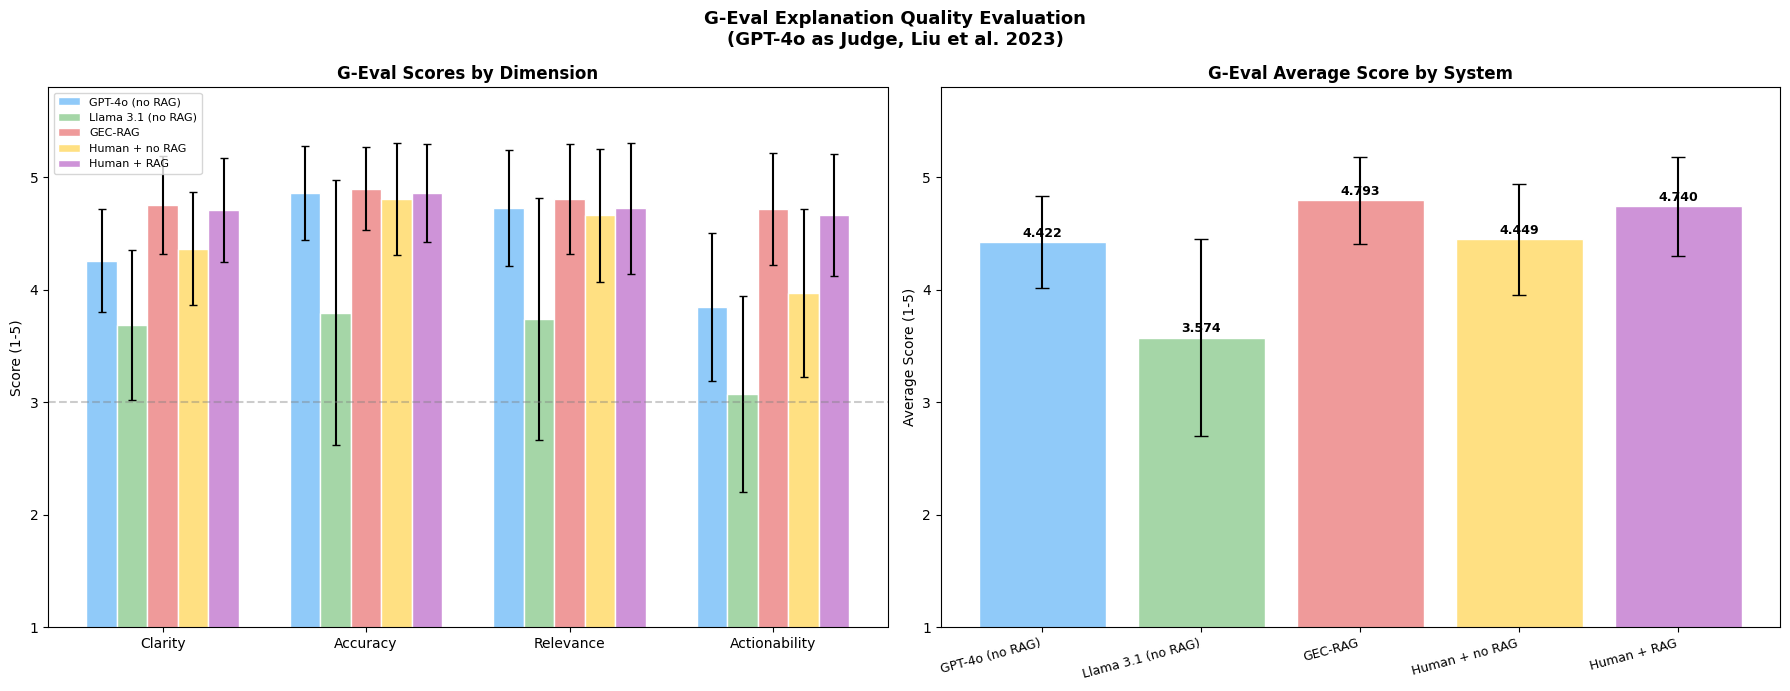

✅ Plot saved: results/geval_results.png


In [10]:
dimensions = ['clarity', 'accuracy', 'relevance', 'actionability']
colors     = ['#90CAF9', '#A5D6A7', '#EF9A9A', '#FFE082', '#CE93D8']

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1 -- Per dimension comparison
x     = np.arange(len(dimensions))
width = 0.15

for i, (s, color) in enumerate(zip(summaries, colors)):
    means = [s[f'{d}_mean'] for d in dimensions]
    stds  = [s[f'{d}_std']  for d in dimensions]
    axes[0].bar(
        x + i*width, means, width,
        yerr=stds, label=s['system'],
        color=color, capsize=3, edgecolor='white'
    )

axes[0].set_xticks(x + width * (len(summaries)-1)/2)
axes[0].set_xticklabels(['Clarity', 'Accuracy', 'Relevance', 'Actionability'])
axes[0].set_ylabel('Score (1-5)')
axes[0].set_ylim(1, 5.8)
axes[0].set_title('G-Eval Scores by Dimension', fontweight='bold')
axes[0].legend(fontsize=8)
axes[0].axhline(y=3, color='gray', linestyle='--', alpha=0.4)

# Plot 2 -- Average score comparison
avg_means = [s['average_mean'] for s in summaries]
avg_stds  = [s['average_std']  for s in summaries]
sys_names = [s['system'] for s in summaries]

bars = axes[1].bar(
    range(len(summaries)), avg_means,
    yerr=avg_stds, color=colors[:len(summaries)],
    capsize=5, edgecolor='white'
)
axes[1].set_xticks(range(len(summaries)))
axes[1].set_xticklabels(sys_names, rotation=15, ha='right', fontsize=9)
axes[1].set_ylabel('Average Score (1-5)')
axes[1].set_ylim(1, 5.8)
axes[1].set_title('G-Eval Average Score by System', fontweight='bold')

for bar, val in zip(bars, avg_means):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.05,
        f'{val:.3f}', ha='center', fontweight='bold', fontsize=9
    )

plt.suptitle(
    'G-Eval Explanation Quality Evaluation\n'
    '(GPT-4o as Judge, Liu et al. 2023)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'geval_results.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f'\u2705 Plot saved: results/geval_results.png')

---
### Cell 9 — Relevance Deep Dive
Relevance is our key claim. This cell shows qualitative evidence.

In [11]:
sep1 = '='*58
sep2 = '-'*55

print(sep1)
print('RELEVANCE ANALYSIS -- KEY CLAIM VALIDATION')
print(sep1)
print(f'\n  {"System":<22} {"Relevance Mean":>16} {"Std":>6}')
print(f'  {"-"*46}')
for s in summaries:
    marker = ' <' if s['system'] == 'GEC-RAG' else (' ^ (ceiling)' if 'Human' in s['system'] else '')
    print(f'  {s["system"]:<22} {s["relevance_mean"]:>14.3f}   {s["relevance_std"]:>5.3f}{marker}')

# Low relevance examples from GPT-4o no RAG
print(f'\n{sep2}')
print('Low relevance examples -- GPT-4o (no RAG)')
print(sep2)
if gpt4o_geval:
    gpt4o_df = pd.DataFrame(gpt4o_geval).sort_values('relevance')
    for _, row in gpt4o_df.head(2).iterrows():
        print(f'  Relevance : {row["relevance"]}/5')
        print(f'  Original  : {row["original"]}')
        print(f'  Corrected : {row["corrected"]}')
        print(f'  Explanation: {row["explanation"][:200]}...')
        print(f'  Reasoning : {row["reasoning"]}')
        print()

# High relevance examples from GEC-RAG
print(sep2)
print('High relevance examples -- GEC-RAG')
print(sep2)
if gecrag_geval:
    gecrag_df = pd.DataFrame(gecrag_geval).sort_values('relevance', ascending=False)
    for _, row in gecrag_df.head(2).iterrows():
        print(f'  Relevance : {row["relevance"]}/5')
        print(f'  Original  : {row["original"]}')
        print(f'  Corrected : {row["corrected"]}')
        print(f'  Explanation: {row["explanation"][:200]}...')
        print(f'  Reasoning : {row["reasoning"]}')
        print()

RELEVANCE ANALYSIS -- KEY CLAIM VALIDATION

  System                   Relevance Mean    Std
  ----------------------------------------------
  GPT-4o (no RAG)                 4.727   0.515
  Llama 3.1 (no RAG)              3.738   1.076
  GEC-RAG                         4.806   0.491 <
  Human + no RAG                  4.660   0.594 ^ (ceiling)
  Human + RAG                     4.724   0.584 ^ (ceiling)

-------------------------------------------------------
Low relevance examples -- GPT-4o (no RAG)
-------------------------------------------------------
  Relevance : 2/5
  Original  : Your friend, Mark
  Corrected : Your friend, Mark.
  Explanation: The original sentence is a fragment and lacks proper punctuation. A period was added at the end to complete the thought....
  Reasoning : The explanation is clear but inaccurately identifies the issue as a fragment; it lacks relevance and actionability as it doesn't explain why a period is needed for a complete sentence.

  Relevance : 2

---
### Cell 10 — Score Distribution Plots

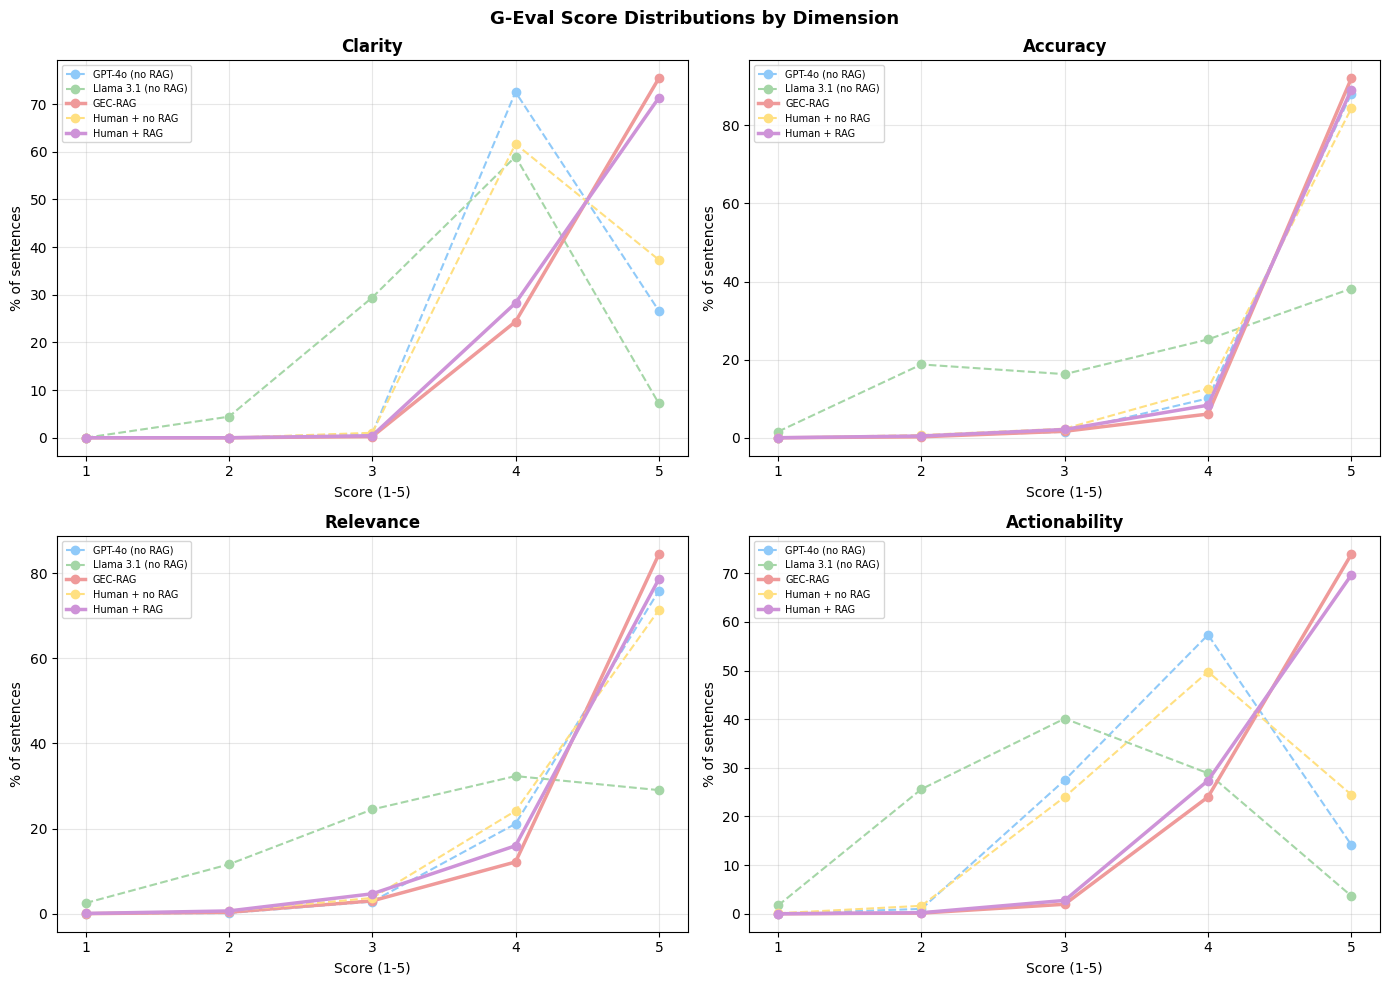

✅ Distribution plot saved: results/geval_distributions.png


In [12]:
all_geval_data = [
    (gpt4o_geval,       'GPT-4o (no RAG)'),
    (llama_geval,       'Llama 3.1 (no RAG)'),
    (gecrag_geval,      'GEC-RAG'),
    (human_norag_geval, 'Human + no RAG'),
    (human_rag_geval,   'Human + RAG'),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
dimensions = ['clarity', 'accuracy', 'relevance', 'actionability']

for ax, dim in zip(axes.flat, dimensions):
    for (data, label), color in zip(all_geval_data, colors):
        if data:
            scores = [r[dim] for r in data]
            total  = len(scores)
            pcts   = [scores.count(i)/total*100 for i in range(1, 6)]
            lw     = 2.5 if label in ['GEC-RAG', 'Human + RAG'] else 1.5
            ls     = '-' if label in ['GEC-RAG', 'Human + RAG'] else '--'
            ax.plot(range(1, 6), pcts, marker='o', color=color,
                    label=label, linewidth=lw, linestyle=ls)

    ax.set_title(dim.capitalize(), fontweight='bold')
    ax.set_xlabel('Score (1-5)')
    ax.set_ylabel('% of sentences')
    ax.set_xticks(range(1, 6))
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle('G-Eval Score Distributions by Dimension',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'geval_distributions.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f'\u2705 Distribution plot saved: results/geval_distributions.png')

---
### Cell 11 — Save All Results

In [13]:
for name, data in [
    ('gpt4o',       gpt4o_geval),
    ('llama',       llama_geval),
    ('gecrag',      gecrag_geval),
    ('human_norag', human_norag_geval),
    ('human_rag',   human_rag_geval),
]:
    if data:
        df   = pd.DataFrame(data)
        path = os.path.join(RESULTS_DIR, f'geval_{name}.csv')
        df.to_csv(path, index=False)
        print(f'\u2705 Saved: {path}')

summary_df   = pd.DataFrame(summaries)
summary_path = os.path.join(RESULTS_DIR, 'geval_summary.csv')
summary_df.to_csv(summary_path, index=False)
print(f'\u2705 Summary saved: {summary_path}')

geval_results = {
    'evaluator' : 'gpt-4o',
    'generator' : 'gpt-4o-mini',
    'method'    : 'G-Eval (Liu et al. 2023)',
    'dimensions': ['clarity', 'accuracy', 'relevance', 'actionability'],
    'scale'     : '1-5',
    'summaries' : summaries,
}
with open(os.path.join(RESULTS_DIR, 'geval_results.json'), 'w') as f:
    json.dump(geval_results, f, indent=2)
print(f'\u2705 Full results saved: results/geval_results.json')

# Save human reference explanations for inspection
for name, data in [('human_norag', human_norag), ('human_rag', human_rag)]:
    if data:
        path = os.path.join(RESULTS_DIR, f'{name}_explanations.json')
        with open(path, 'w', encoding='utf-8') as f:
            json.dump(data, f, ensure_ascii=False, indent=2)
        print(f'\u2705 Saved: {path}')

✅ Saved: C:/gecrag\results\geval_gpt4o.csv
✅ Saved: C:/gecrag\results\geval_llama.csv
✅ Saved: C:/gecrag\results\geval_gecrag.csv
✅ Saved: C:/gecrag\results\geval_human_norag.csv
✅ Saved: C:/gecrag\results\geval_human_rag.csv
✅ Summary saved: C:/gecrag\results\geval_summary.csv
✅ Full results saved: results/geval_results.json
✅ Saved: C:/gecrag\results\human_norag_explanations.json
✅ Saved: C:/gecrag\results\human_rag_explanations.json


---
### Cell 12 — Combined Results Table for Paper

In [14]:
with open(os.path.join(RESULTS_DIR, 'baseline_scores.json'), 'r') as f:
    f05_scores = json.load(f)

system_to_f05 = {
    'GPT-4o (no RAG)'    : 'GPT-4o-mini (no RAG)',
    'Llama 3.1 (no RAG)' : 'Llama-3.1-8B (no RAG)',
    'GEC-RAG'            : 'GEC-RAG (GPT-4o-mini + KB)',
    'Human + no RAG'     : None,
    'Human + RAG'        : None,
}

sep = '='*90
print(sep)
print('COMPLETE RESULTS TABLE')
print('Correction Quality (F0.5) + Explanation Quality (G-Eval, 1-5)')
print(sep)
print(f'\n  {"System":<22} {"F0.5":>6} | {"Clarity":>8} {"Accuracy":>9} {"Relevance":>10} {"Action":>8} {"Avg":>6}')
print(f'  {"-"*86}')

# T5-GEC first (no explanation)
t5_f05 = f05_scores.get('T5-GEC', {}).get('f05', 'N/A')
print(f'  {"T5-GEC":<22} {t5_f05:>5}% | {"N/A":>7}  {"N/A":>8}  {"N/A":>9}  {"N/A":>7} {"N/A":>6}')

# Other systems
for s in summaries:
    f05_key = system_to_f05.get(s['system'])
    f05_val = f05_scores.get(f05_key, {}).get('f05', 'N/A') if f05_key else 'N/A'
    f05_str = f'{f05_val}%' if f05_val != 'N/A' else 'N/A'
    marker  = ' <' if s['system'] == 'GEC-RAG' else (' ^' if 'Human' in s['system'] else '')
    print(
        f'  {s["system"]:<22} {f05_str:>6} | '
        f'{s["clarity_mean"]:>7.3f}  '
        f'{s["accuracy_mean"]:>8.3f}  '
        f'{s["relevance_mean"]:>9.3f}  '
        f'{s["actionability_mean"]:>7.3f} '
        f'{s["average_mean"]:>6.3f}{marker}'
    )

print(f'\n  < = Our proposed system | ^ = Human upper bound (reference corrections)')
print(f'  Human conditions: F0.5 not applicable (uses reference corrections directly)')
print(f'  T5-GEC: G-Eval not applicable (produces no explanation)')

print(f'\n\u26a0\ufe0f  Reminder: If you ran with MAX_SENTENCES=100,')
print(f'   set MAX_SENTENCES=None in Cells 4 and 6 and re-run cells 4-11.')

print(f'\n\U0001f4c1 Output Files:')
print(f'   - results/geval_*.csv (per-system scores)')
print(f'   - results/geval_summary.csv')
print(f'   - results/geval_results.json')
print(f'   - results/geval_results.png')
print(f'   - results/geval_distributions.png')

print(f'\n\u27a1\ufe0f  Next: Run Notebook 08 -- Analysis & Paper Figures')

COMPLETE RESULTS TABLE
Correction Quality (F0.5) + Explanation Quality (G-Eval, 1-5)

  System                   F0.5 |  Clarity  Accuracy  Relevance   Action    Avg
  --------------------------------------------------------------------------------------
  T5-GEC                 40.93% |     N/A       N/A        N/A      N/A    N/A
  GPT-4o (no RAG)        39.82% |   4.258     4.858      4.727    3.846  4.422
  Llama 3.1 (no RAG)     33.08% |   3.689     3.797      3.738    3.072  3.574
  GEC-RAG                 39.8% |   4.752     4.899      4.806    4.717  4.793 <
  Human + no RAG            N/A |   4.363     4.805      4.660    3.969  4.449 ^
  Human + RAG               N/A |   4.709     4.861      4.724    4.665  4.740 ^

  < = Our proposed system | ^ = Human upper bound (reference corrections)
  Human conditions: F0.5 not applicable (uses reference corrections directly)
  T5-GEC: G-Eval not applicable (produces no explanation)

⚠️  Reminder: If you ran with MAX_SENTENCES=100,
   s